In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yashdev01/spotify-tracks-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/yashdev01/spotify-tracks-dataset


In [7]:
import os
import pandas as pd

files = [f for f in os.listdir(path) if f.endswith(".csv")]
print(files)

df = pd.read_csv(os.path.join(path, files[0]))
df.shape

['spotify-tracks-dataset.csv']


(114000, 22)

In [8]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'track_id', 'artists', 'album_name',
       'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability',
       'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='object')

In [9]:
df.head()

,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [10]:
# drop the two useless index columns
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

# how many missing values per column?
print(df.isnull().sum())

# the same song can appear under several genres, so check for repeats
print(df.duplicated(subset="track_id").sum())

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
24259


In [11]:
df = df.drop_duplicates(subset="track_id").dropna()
df.shape

(89740, 20)

In [12]:
def get_mood(row):
    if row["valence"] >= 0.5 and row["energy"] >= 0.5:
        return "Happy"
    elif row["valence"] >= 0.5 and row["energy"] < 0.5:
        return "Calm"
    elif row["valence"] < 0.5 and row["energy"] < 0.5:
        return "Sad"
    else:
        return "Angry/Tense"

df["mood"] = df.apply(get_mood, axis=1)
df["mood"].value_counts()

mood
Happy          33220
Angry/Tense    30211
Sad            19030
Calm            7279
Name: count, dtype: int64

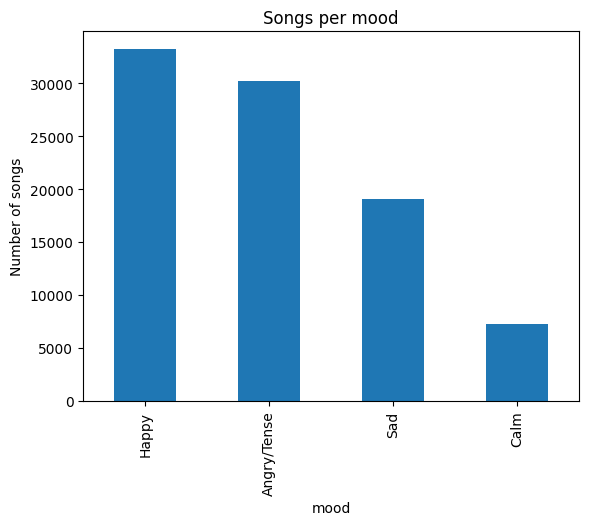

In [13]:
import matplotlib.pyplot as plt

# Chart 1: how many songs per mood
df["mood"].value_counts().plot(kind="bar", title="Songs per mood")
plt.ylabel("Number of songs")
plt.show()

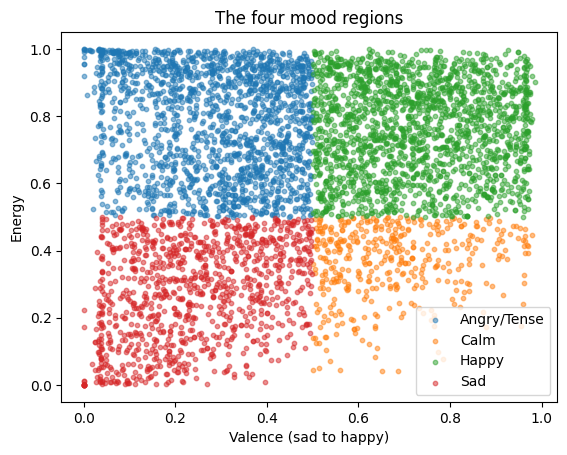

In [14]:
# Chart 2: valence vs energy, colored by mood (a sample, so it's not too crowded)
sample = df.sample(5000, random_state=42)
for mood, group in sample.groupby("mood"):
    plt.scatter(group["valence"], group["energy"], label=mood, alpha=0.5, s=10)
plt.xlabel("Valence (sad to happy)")
plt.ylabel("Energy")
plt.legend()
plt.title("The four mood regions")
plt.show()

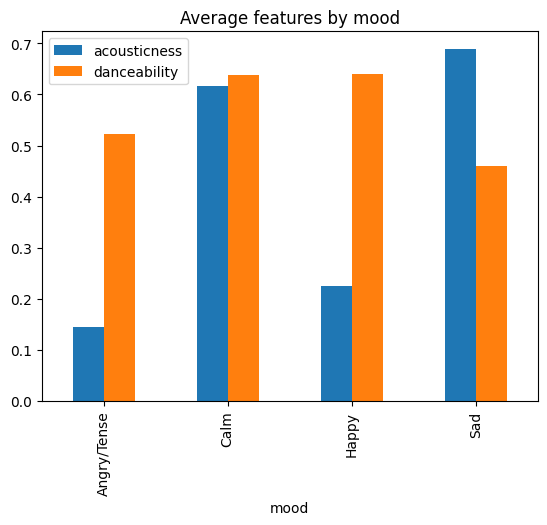

In [15]:
# Chart 3: average acousticness and danceability per mood
df.groupby("mood")[["acousticness", "danceability"]].mean().plot(kind="bar", title="Average features by mood")
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

features = ["danceability", "acousticness", "tempo", "speechiness",
            "instrumentalness", "liveness", "mode", "key", "duration_ms"]

X = df[features]
y = df["mood"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                               random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

 Angry/Tense       0.70      0.68      0.69      6042
        Calm       0.62      0.32      0.43      1456
       Happy       0.67      0.74      0.70      6644
         Sad       0.73      0.74      0.74      3806

    accuracy                           0.69     17948
   macro avg       0.68      0.62      0.64     17948
weighted avg       0.69      0.69      0.68     17948



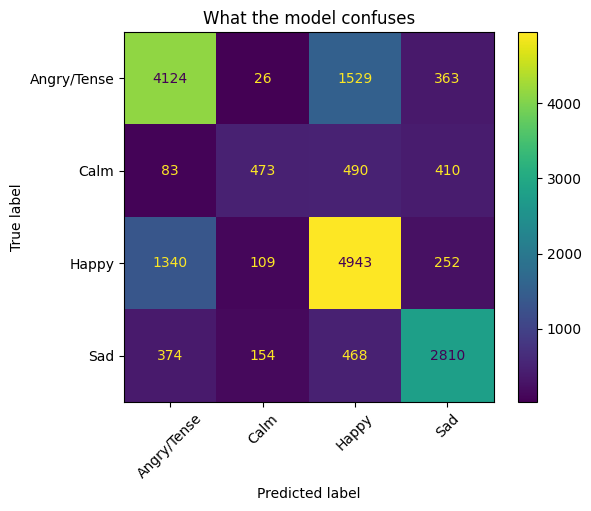

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=45)
plt.title("What the model confuses")
plt.show()

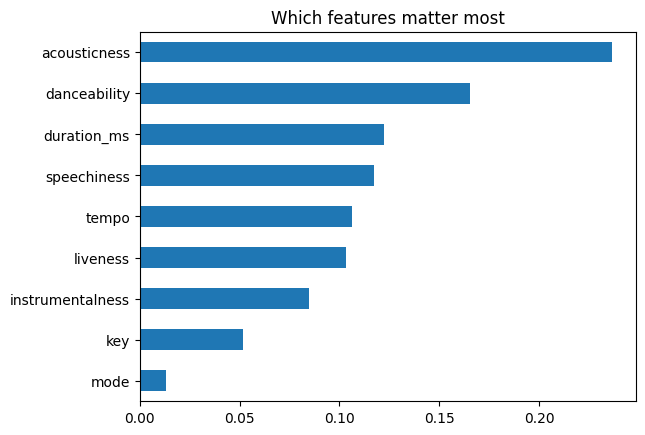

In [18]:
import pandas as pd

importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", title="Which features matter most")
plt.show()